# Visualizing the Impact of COVID on life, liberty and happiness
Analyzing both how governments and people responded to the implications of COVID-19. 

### Authored by Duy Nguyen, Rashmi Kamath, Alex Song and Brisa Halviatti
### DATA 5310

## Loading Data and Importing Libraries

Libraries

In [83]:
import io
import os
import unicodedata
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import altair as alt

In [50]:
# our four countries: the name every table uses, and the 3-letter code OWID and Oxford use
COUNTRIES = {'United States': 'USA', 'India': 'IND', 'South Korea': 'KOR', 'Vietnam': 'VNM'}
# Google names its files with 2-letter codes instead
GOOGLE_CODES = {'US': 'United States', 'IN': 'India', 'KR': 'South Korea', 'VN': 'Vietnam'}

START, END = '2020-01-01', '2022-12-31'                 # Oxford's full range
GOOGLE_START, GOOGLE_END = '2020-02-15', '2022-10-15'   # Google's full range

OWID_URL = 'https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv'
# pinned to one commit so everyone gets the same file
OXFORD_URL = ('https://raw.githubusercontent.com/OxCGRT/covid-policy-dataset/'
              'e7f66ee39654293b5c068efd2f195bd591dc27f6/data/OxCGRT_compact_national_v1.csv')
GOOGLE_URL = 'https://www.gstatic.com/covid19/mobility/Region_Mobility_Report_CSVs.zip'

IND_SURV_URL = 'https://raw.githubusercontent.com/YouGov-Data/covid-19-tracker/refs/heads/master/data/india.csv'
KOR_SURV_URL = 'https://raw.githubusercontent.com/YouGov-Data/covid-19-tracker/refs/heads/master/data/south-korea.csv'
USA_SURV_URL = 'https://raw.githubusercontent.com/YouGov-Data/covid-19-tracker/refs/heads/master/data/united-states.zip'
VNM_SURV_URL = 'https://raw.githubusercontent.com/YouGov-Data/covid-19-tracker/refs/heads/master/data/vietnam.csv'

# where section 9 saves the clean tables (on Colab this folder is wiped when the session ends;
# set SAVE_TO_DRIVE = True to keep them in your Google Drive instead)
CLEAN_DIR = os.path.join('data', 'clean')
SAVE_TO_DRIVE = False
DRIVE_DIR = '/content/drive/MyDrive/DATA5310_covid/clean'

### Load the raw data

In [52]:
owid_raw = pd.read_csv(OWID_URL, parse_dates=['date'])
oxford_raw = pd.read_csv(OXFORD_URL, low_memory=False)
ind_survey_raw_df = pd.read_csv(IND_SURV_URL)
kor_survey_raw_df = pd.read_csv(KOR_SURV_URL)
usa_survey_raw_df = pd.read_csv(USA_SURV_URL)
vnm_survey_raw_df = pd.read_csv(VNM_SURV_URL)

# send a browser name with the request, to be safe
request = urllib.request.Request(GOOGLE_URL, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(request) as response:
    google_zip = zipfile.ZipFile(io.BytesIO(response.read()))

google_parts = []
for name in sorted(google_zip.namelist()):
    code = name.split('_')[1] if name.endswith('_Region_Mobility_Report.csv') else None
    if code in GOOGLE_CODES:                       # e.g. '2021_VN_Region_Mobility_Report.csv'
        part = pd.read_csv(google_zip.open(name), parse_dates=['date'], low_memory=False)
        part = part[part['sub_region_2'].isna() & part['metro_area'].isna()]   # no counties / metro areas
        google_parts.append(part.assign(country=GOOGLE_CODES[code]))
google_raw = pd.concat(google_parts, ignore_index=True)

for name, df in [('owid_raw', owid_raw), ('oxford_raw', oxford_raw), ('google_raw', google_raw)]:
    print(f'{name:11s} {df.shape[0]:>8,} rows x {df.shape[1]} columns')

C:\Users\brisa\AppData\Local\Temp\ipykernel_7240\1259366357.py:3: DtypeWarning: Columns (81) have mixed types. Specify dtype option on import or set low_memory=False.
  ind_survey_raw_df = pd.read_csv(IND_SURV_URL)
C:\Users\brisa\AppData\Local\Temp\ipykernel_7240\1259366357.py:4: DtypeWarning: Columns (5,7,34,78,322,323,324,325,326,327,328,329,330,331,332,333,334,335,336,337,338,339,340,341,342,343,344,345,346,347,348,349,350,351,352,353,354) have mixed types. Specify dtype option on import or set low_memory=False.
  kor_survey_raw_df = pd.read_csv(KOR_SURV_URL)
C:\Users\brisa\AppData\Local\Temp\ipykernel_7240\1259366357.py:5: DtypeWarning: Columns (4,6,42,81,90,390,391,392,393,394,395,396,397,398,399,400,401,402,403,404,405,406,407,408,409,410,411,412,413,414,415,416,417,418,419,420,421,422,423) have mixed types. Specify dtype option on import or set low_memory=False.
  usa_survey_raw_df = pd.read_csv(USA_SURV_URL)
C:\Users\brisa\AppData\Local\Temp\ipykernel_7240\1259366357.py:6: Dtyp

owid_raw     629,868 rows x 61 columns
oxford_raw   202,760 rows x 56 columns
google_raw   149,940 rows x 16 columns


#### OWID: cases, deaths, vaccinations

1. Keep real countries only. Groups like `World` or `High-income countries` have no continent.
   Keep countries with more than 1 million people (Rashmi's rule, so tiny places don't create extreme values).
2. Keep the columns we use. I drop OWID's copy of `stringency_index` on purpose: we take the index
   from Oxford's own file, so there is only one version of it (the two are identical). I also drop the
   hospital, ICU and excess-death columns: India and Vietnam have none, so we can't compare all four
   (the US and South Korea do have them in the raw `compact.csv`).
3. After a country's last real report, OWID fills new cases and deaths with 0 for years. Those are
   not real zeros, so I blank them. (Same for the two countries that never report a case: North Korea
   and Turkmenistan.) Nothing is blanked for our four countries before 2023.
4. `owid` is our four countries, Jan 2020 to Dec 2022. I don't fill gaps here: vaccination numbers are
   only filled forward in `daily` (step 5).

In [53]:
OWID_COLUMNS = [
    'country', 'code', 'continent', 'date', 'population', 'gdp_per_capita', 'median_age',
    # cases
    'total_cases', 'new_cases', 'new_cases_smoothed',
    'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million',
    # deaths
    'total_deaths', 'new_deaths', 'new_deaths_smoothed',
    'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million',
    # vaccinations per 100 people (total_ and boosters count doses, so they can pass 100)
    'total_vaccinations_per_hundred', 'people_vaccinated_per_hundred',
    'people_fully_vaccinated_per_hundred', 'total_boosters_per_hundred',
    'new_people_vaccinated_smoothed_per_hundred', 'new_vaccinations_smoothed_per_million',
    # testing (stops in June 2022 for all four; Vietnam's only starts in Sep 2021)
    'new_tests_smoothed_per_thousand', 'positive_rate',
]
CASE_COLUMNS = ['new_cases', 'new_cases_smoothed', 'new_cases_per_million', 'new_cases_smoothed_per_million']
DEATH_COLUMNS = ['new_deaths', 'new_deaths_smoothed', 'new_deaths_per_million', 'new_deaths_smoothed_per_million']

real_countries = owid_raw['continent'].notna() & (owid_raw['population'] > 1_000_000)
owid_world = (owid_raw.loc[real_countries, OWID_COLUMNS]
              .rename(columns={'code': 'country_code'})
              .sort_values(['country', 'date'])
              .reset_index(drop=True))


def blank_after_last_report(df, report_column, columns):
    # days after a country's last non-zero report are filler zeros, not real zeros
    last_report = df.loc[df[report_column] > 0].groupby('country')['date'].max()
    # countries that never report a positive value get an early date, so all their rows are blanked
    after = df['date'] > df['country'].map(last_report).fillna(pd.Timestamp('1900-01-01'))
    df.loc[after, columns] = np.nan
    return after.sum()


n_cases = blank_after_last_report(owid_world, 'new_cases', CASE_COLUMNS)
n_deaths = blank_after_last_report(owid_world, 'new_deaths', DEATH_COLUMNS)
print(f'blanked filler zeros: {n_cases:,} country-days of cases, {n_deaths:,} of deaths')

owid = (owid_world[owid_world['country'].isin(COUNTRIES) & owid_world['date'].between(START, END)]
        .reset_index(drop=True))
print(f'owid_world: {owid_world["country"].nunique()} countries, {len(owid_world):,} rows')
print(f'owid:       {len(owid):,} rows')
owid.head()

blanked filler zeros: 95,777 country-days of cases, 162,679 of deaths
owid_world: 161 countries, 396,503 rows
owid:       4,384 rows


,country,country_code,continent,date,population,gdp_per_capita,median_age,total_cases,new_cases,new_cases_smoothed,...,new_deaths_per_million,new_deaths_smoothed_per_million,total_vaccinations_per_hundred,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,total_boosters_per_hundred,new_people_vaccinated_smoothed_per_hundred,new_vaccinations_smoothed_per_million,new_tests_smoothed_per_thousand,positive_rate
0,India,IND,Asia,2020-01-01,1.425423e+09,10039.071289,27.684,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,India,IND,Asia,2020-01-02,1.425423e+09,10039.071289,27.684,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,India,IND,Asia,2020-01-03,1.425423e+09,10039.071289,27.684,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,India,IND,Asia,2020-01-04,1.425423e+09,10039.071289,27.684,0.0,0.0,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,India,IND,Asia,2020-01-05,1.425423e+09,10039.071289,27.684,0.0,0.0,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Oxford (OxCGRT): the rules

Same as Alex's EDA, with the same column names, plus two things I think we would need later:

- **Flags** (`_flag` columns): `1` means the rule applied to the whole country, `0` means only some
  regions. Blank when there was no rule that day (level 0), so they come back as 0.0/1.0 from a CSV.
  (I left out the vaccination-policy flag: it means cost, not place, and is always 1 for our four.)
- **`majority_vaccinated`**: from 2021, Oxford records some rules separately for vaccinated and
  unvaccinated people. The `M` columns (e.g. `stay_at_home`) show the rule for the majority. `True`
  means most people were vaccinated, so the rule shown is the one for vaccinated people.

The two indices are Oxford's `_Average` versions: an average of the vaccinated and unvaccinated
indices, weighted by the share vaccinated. So from 2021 the index can differ from what the `M` columns
alone suggest (by up to about 10 points for the US). The compact file has no separate vaccinated or
unvaccinated index, so any chart of the index after 2020 needs that caveat.

In [54]:
level_names = {
    'C1M_School closing': 'school_closing', 'C2M_Workplace closing': 'workplace_closing',
    'C3M_Cancel public events': 'cancel_public_events', 'C4M_Restrictions on gatherings': 'gathering_limits',
    'C5M_Close public transport': 'close_public_transport', 'C6M_Stay at home requirements': 'stay_at_home',
    'C7M_Restrictions on internal movement': 'internal_movement_limits',
    'C8EV_International travel controls': 'international_travel_controls',
    'H2_Testing policy': 'testing_policy', 'H3_Contact tracing': 'contact_tracing',
    'H6M_Facial Coverings': 'face_coverings', 'H7_Vaccination policy': 'vaccination_policy',
}
flag_names = {
    'C1M_Flag': 'school_closing_flag', 'C2M_Flag': 'workplace_closing_flag',
    'C3M_Flag': 'cancel_public_events_flag', 'C4M_Flag': 'gathering_limits_flag',
    'C5M_Flag': 'close_public_transport_flag', 'C6M_Flag': 'stay_at_home_flag',
    'C7M_Flag': 'internal_movement_limits_flag', 'H6M_Flag': 'face_coverings_flag',
}
index_names = {'StringencyIndex_Average': 'stringency_index',
               'ContainmentHealthIndex_Average': 'containment_health_index'}
oxford_rename = {'CountryName': 'country', 'CountryCode': 'country_code', 'Date': 'date',
                 **level_names, **flag_names, **index_names, 'MajorityVaccinated': 'majority_vaccinated'}

oxford = (oxford_raw[oxford_raw['CountryCode'].isin(COUNTRIES.values())]
          [list(oxford_rename)].rename(columns=oxford_rename))

# real dates (Oxford stores them as numbers like 20200415), plus year and month for grouping
oxford['date'] = pd.to_datetime(oxford['date'].astype(str), format='%Y%m%d')
oxford['year'] = oxford['date'].dt.year
oxford['month'] = oxford['date'].dt.to_period('M').dt.to_timestamp()

# whole-number levels; flags stay blank on days with no rule
levels, flags = list(level_names.values()), list(flag_names.values())
assert oxford[levels].notna().all().all(), 'a policy level is blank'
oxford[levels] = oxford[levels].astype(int)
oxford[flags] = oxford[flags].astype('Int64')
oxford['majority_vaccinated'] = oxford['majority_vaccinated'].eq('V')
oxford['stay_at_home_label'] = oxford['stay_at_home'].map(
    {0: 'none', 1: 'recommended', 2: 'required (essentials OK)', 3: 'required (few exceptions)'})

oxford = oxford.sort_values(['country', 'date']).reset_index(drop=True)
print(f'oxford: {len(oxford):,} rows, {oxford["date"].min():%b %d, %Y} to {oxford["date"].max():%b %d, %Y}')
oxford.head()

oxford: 4,384 rows, Jan 01, 2020 to Dec 31, 2022


,country,country_code,date,school_closing,workplace_closing,cancel_public_events,gathering_limits,close_public_transport,stay_at_home,internal_movement_limits,...,close_public_transport_flag,stay_at_home_flag,internal_movement_limits_flag,face_coverings_flag,stringency_index,containment_health_index,majority_vaccinated,year,month,stay_at_home_label
0,India,IND,2020-01-01,0,0,0,0,0,0,0,...,<NA>,<NA>,<NA>,<NA>,0.0,0.0,False,2020,2020-01-01,none
1,India,IND,2020-01-02,0,0,0,0,0,0,0,...,<NA>,<NA>,<NA>,<NA>,0.0,0.0,False,2020,2020-01-01,none
2,India,IND,2020-01-03,0,0,0,0,0,0,0,...,<NA>,<NA>,<NA>,<NA>,0.0,0.0,False,2020,2020-01-01,none
3,India,IND,2020-01-04,0,0,0,0,0,0,0,...,<NA>,<NA>,<NA>,<NA>,0.0,0.0,False,2020,2020-01-01,none
4,India,IND,2020-01-05,0,0,0,0,0,0,0,...,<NA>,<NA>,<NA>,<NA>,0.0,0.0,False,2020,2020-01-01,none


#### Google mobility: visits compared with each place's own normal

1. Shorten the six column names (`retail_and_recreation_percent_change_from_baseline` becomes `retail`).
2. `google` is the whole-country row (no state or province name). `google_regions` is the states and
   provinces, with plain names (no accents, no "Province") and their ISO code, which is the safer key.
3. Leave gaps blank, as Google asks. Some provinces are missing whole days (no row at all), so I add
   those days back as blank rows. That way every place has every day, and 7-day averages line up.

Google's own warnings still apply: compare each place only with itself, never one country's level
with another's. The baseline (Jan 3 - Feb 6, 2020) includes Lunar New Year in Vietnam and South Korea,
and holidays look like lockdowns.

In [55]:
MEASURES = {'retail_and_recreation_percent_change_from_baseline': 'retail',
            'grocery_and_pharmacy_percent_change_from_baseline': 'grocery',
            'parks_percent_change_from_baseline': 'parks',
            'transit_stations_percent_change_from_baseline': 'transit',
            'workplaces_percent_change_from_baseline': 'workplaces',
            'residential_percent_change_from_baseline': 'residential'}
measures = list(MEASURES.values())


def plain_name(name):
    # 'Bắc Kạn Province' -> 'Bac Kan'
    name = name.removesuffix(' Province').replace('Đ', 'D').replace('đ', 'd')
    return ''.join(ch for ch in unicodedata.normalize('NFKD', name) if not unicodedata.combining(ch))


mob = google_raw.rename(columns=MEASURES)
mob['country_code'] = mob['country'].map(COUNTRIES)
national = mob['sub_region_1'].isna()

google = (mob.loc[national, ['country', 'country_code', 'date'] + measures]
          .sort_values(['country', 'date']).reset_index(drop=True))

regions = mob.loc[~national].assign(region=lambda d: d['sub_region_1'].map(plain_name),
                                    region_code=lambda d: d['iso_3166_2_code'])
# every place gets every day: missing days come back as blank rows
all_days = pd.date_range(GOOGLE_START, GOOGLE_END, freq='D')
places = regions[['country', 'country_code', 'region', 'region_code']].drop_duplicates()
full_grid = places.merge(pd.DataFrame({'date': all_days}), how='cross')
google_regions = (full_grid.merge(regions[['region_code', 'date'] + measures],
                                  on=['region_code', 'date'], how='left')
                  .sort_values(['country', 'region', 'date']).reset_index(drop=True))

print(f'google:         {len(google):,} rows')
print(f'google_regions: {len(google_regions):,} rows, '
      f'{google_regions.groupby("country")["region_code"].nunique().to_dict()} regions, '
      f'{len(google_regions) - len(regions):,} missing days added back as blank rows')
google.head()

google:         3,896 rows
google_regions: 146,100 rows, {'India': 36, 'United States': 51, 'Vietnam': 63} regions, 56 missing days added back as blank rows


,country,country_code,date,retail,grocery,parks,transit,workplaces,residential
0,India,IND,2020-02-15,1.0,2.0,3.0,3.0,5.0,0.0
1,India,IND,2020-02-16,2.0,2.0,3.0,2.0,0.0,0.0
2,India,IND,2020-02-17,-1.0,1.0,3.0,1.0,4.0,0.0
3,India,IND,2020-02-18,0.0,2.0,4.0,2.0,3.0,0.0
4,India,IND,2020-02-19,0.0,2.0,1.0,1.0,4.0,1.0


#### YouGov Data: Survey data to capture people's sentiments, compliance, and responses

The description of the columns can be found here: https://github.com/YouGov-Data/covid-19-tracker/blob/master/codebook.xlsx

In [56]:
ind_survey_raw_df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16145 entries, 0 to 16144
Data columns (total 334 columns):
 #    Column              Non-Null Count  Dtype  
---   ------              --------------  -----  
 0    RecordNo            16145 non-null  int64  
 1    endtime             16145 non-null  object 
 2    gender              16145 non-null  object 
 3    state               16145 non-null  object 
 4    qweek               16145 non-null  object 
 5    i1_health           16145 non-null  int64  
 6    i2_health           16145 non-null  int64  
 7    i7a_health          16145 non-null  int64  
 8    i3_health           16145 non-null  object 
 9    i4_health           16145 non-null  object 
 10   i5_health_1         16145 non-null  object 
 11   i5_health_2         16145 non-null  object 
 12   i5_health_3         16145 non-null  object 
 13   i5_health_4         16145 non-null  object 
 14   i5_health_5         16145 non-null  object 
 15   i5_health_99        16145 non-null

In [57]:
kor_survey_raw_df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18526 entries, 0 to 18525
Data columns (total 355 columns):
 #    Column              Non-Null Count  Dtype  
---   ------              --------------  -----  
 0    RecordNo            18526 non-null  int64  
 1    endtime             18526 non-null  object 
 2    qweek               18526 non-null  object 
 3    gender              18526 non-null  object 
 4    region              18526 non-null  object 
 5    i1_health           18526 non-null  object 
 6    i2_health           18526 non-null  int64  
 7    i7a_health          18526 non-null  object 
 8    i5a_health          18526 non-null  object 
 9    i6_health           18526 non-null  object 
 10   i8_health           18526 non-null  object 
 11   i9_health           18526 non-null  object 
 12   i10_health          18526 non-null  object 
 13   i11_health          18526 non-null  object 
 14   i12_health_1        18526 non-null  object 
 15   i12_health_2        18526 non-null

In [58]:
usa_survey_raw_df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33940 entries, 0 to 33939
Data columns (total 424 columns):
 #    Column              Non-Null Count  Dtype  
---   ------              --------------  -----  
 0    RecordNo            33940 non-null  int64  
 1    endtime             33940 non-null  object 
 2    state               33940 non-null  object 
 3    qweek               33940 non-null  object 
 4    i1_health           33940 non-null  object 
 5    i2_health           33940 non-null  int64  
 6    i7a_health          33940 non-null  object 
 7    i3_health           33940 non-null  object 
 8    i4_health           33940 non-null  object 
 9    i5_health_1         33940 non-null  object 
 10   i5_health_2         33940 non-null  object 
 11   i5_health_3         33940 non-null  object 
 12   i5_health_4         33940 non-null  object 
 13   i5_health_5         33940 non-null  object 
 14   i5_health_99        33940 non-null  object 
 15   i5a_health          33940 non-null

In [59]:
vnm_survey_raw_df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12074 entries, 0 to 12073
Data columns (total 330 columns):
 #    Column               Non-Null Count  Dtype  
---   ------               --------------  -----  
 0    RecordNo             12074 non-null  int64  
 1    endtime              12074 non-null  object 
 2    region               12074 non-null  object 
 3    qweek                12074 non-null  object 
 4    i1_health            12074 non-null  int64  
 5    i2_health            12074 non-null  int64  
 6    i7a_health           12074 non-null  int64  
 7    i5a_health           12074 non-null  object 
 8    i6_health            12074 non-null  object 
 9    i8_health            12074 non-null  object 
 10   i9_health            12074 non-null  object 
 11   i10_health           12074 non-null  object 
 12   i11_health           12074 non-null  object 
 13   i12_health_1         12074 non-null  object 
 14   i12_health_2         12074 non-null  object 
 15   i12_health_3     

Keep only the columns that exist in all four dfs

In [60]:
dfs = [ind_survey_raw_df, kor_survey_raw_df, usa_survey_raw_df, vnm_survey_raw_df]

common_cols = [col for col in ind_survey_raw_df.columns
               if all(col in df.columns for df in dfs)]

print(len(common_cols))
common_cols

230


['RecordNo',
 'endtime',
 'gender',
 'qweek',
 'i1_health',
 'i2_health',
 'i7a_health',
 'i3_health',
 'i4_health',
 'i5_health_1',
 'i5_health_2',
 'i5_health_3',
 'i5_health_4',
 'i5_health_5',
 'i5_health_99',
 'i5a_health',
 'i6_health',
 'i7b_health',
 'i8_health',
 'i9_health',
 'i10_health',
 'i11_health',
 'i12_health_1',
 'i12_health_2',
 'i12_health_3',
 'i12_health_4',
 'i12_health_5',
 'i12_health_6',
 'i12_health_7',
 'i12_health_8',
 'i12_health_9',
 'i12_health_10',
 'i12_health_11',
 'i12_health_12',
 'i12_health_13',
 'i12_health_14',
 'i12_health_15',
 'i12_health_16',
 'i12_health_17',
 'i12_health_18',
 'i12_health_19',
 'i12_health_20',
 'i13_health',
 'i14_health_1',
 'i14_health_2',
 'i14_health_3',
 'i14_health_4',
 'i14_health_5',
 'i14_health_6',
 'i14_health_7',
 'i14_health_8',
 'i14_health_9',
 'i14_health_10',
 'i14_health_96',
 'i14_health_98',
 'i14_health_99',
 'i14_health_other',
 'd1_health_1',
 'd1_health_2',
 'd1_health_3',
 'd1_health_4',
 'd1_hea

In [61]:
kor_survey_raw_df['weight'].describe()
## according to the README this is survey weight, not body weight

count    18526.000000
mean         1.000000
std          0.293492
min          0.357545
25%          0.846442
50%          0.950236
75%          1.107155
max          4.276181
Name: weight, dtype: float64

Reading the column descriptions, we select shared columns of interest and put together a new DF for all the data we care about in our countries of interest

In [62]:
cols = ['endtime', 'gender', 'i2_health', 'i7a_health', 'i9_health', 'i10_health', 'i11_health',
        'i12_health_1', 'i12_health_6', 'i12_health_8', 'i12_health_11', 'i12_health_12',
        'i12_health_13', 'i12_health_14', 'i12_health_15', 'i12_health_16', 'age',
        'household_size', 'household_children', 'WCRV_4', 'PHQ4_1', 'PHQ4_2', 'PHQ4_3',
        'PHQ4_4', 'WCRex1', 'ct4', 'ox3_1', 'ox3_2', 'ox3_3', 'ox3_4', 'ox3_5', 'ox3_6',
        'ox5_2', 'ox6','weight']

raw = {'India': ind_survey_raw_df, 'South Korea': kor_survey_raw_df,
       'United States': usa_survey_raw_df, 'Vietnam': vnm_survey_raw_df}

surv_df = pd.concat([df[cols].assign(country=code) for code, df in raw.items()],
                    ignore_index=True)

# Blank strings count as missing
surv_df = surv_df.replace(r'^\s*$', pd.NA, regex=True)

# Drop columns that are more than 80% null
surv_df = surv_df.loc[:, surv_df.notna().mean() >= 0.2]

# Move country to the front; parse endtime (day-first, e.g. 01/04/2020 = 1 April)
surv_df = surv_df[['country'] + [c for c in surv_df.columns if c != 'country']]
surv_df['endtime'] = pd.to_datetime(surv_df['endtime'], dayfirst=True, errors='coerce')

surv_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80685 entries, 0 to 80684
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   country             80685 non-null  object        
 1   endtime             80685 non-null  datetime64[ns]
 2   gender              80685 non-null  object        
 3   i2_health           80685 non-null  int64         
 4   i7a_health          71782 non-null  object        
 5   i9_health           77250 non-null  object        
 6   i10_health          68347 non-null  object        
 7   i11_health          77250 non-null  object        
 8   i12_health_1        80685 non-null  object        
 9   i12_health_6        80685 non-null  object        
 10  i12_health_8        80685 non-null  object        
 11  i12_health_11       80685 non-null  object        
 12  i12_health_12       80685 non-null  object        
 13  i12_health_13       80685 non-null  object    

Using the codebook, add more descriptive column names so we don't have to go back and forth looking at the codes

In [63]:
rename_map = {
    'endtime': 'survey_date',
    'i2_health': 'contacts_outside_household',
    'i7a_health': 'times_left_home_yesterday',
    'i9_health': 'would_isolate_if_symptomatic',
    'i10_health': 'isolation_ease',
    'i11_health': 'isolation_willingness',
    'i12_health_1': 'wore_mask_outside',
    'i12_health_6': 'avoided_going_out',
    'i12_health_8': 'avoided_public_transport',
    'i12_health_11': 'avoided_home_guests',
    'i12_health_12': 'avoided_small_gatherings',
    'i12_health_13': 'avoided_medium_gatherings',
    'i12_health_14': 'avoided_large_gatherings',
    'i12_health_15': 'avoided_crowded_areas',
    'i12_health_16': 'avoided_shops',
    'WCRV_4': 'fear_of_contracting',
    'PHQ4_1': 'phq4_low_interest',
    'PHQ4_2': 'phq4_feeling_down',
    'PHQ4_3': 'phq4_anxious',
    'PHQ4_4': 'phq4_cant_stop_worrying',
    'WCRex1': 'govt_handling_rating',
    'weight': 'survey_weight'
}

surv_df = surv_df.rename(columns=rename_map)
surv_df.head()

,country,survey_date,gender,contacts_outside_household,times_left_home_yesterday,would_isolate_if_symptomatic,isolation_ease,isolation_willingness,wore_mask_outside,avoided_going_out,...,age,household_size,household_children,fear_of_contracting,phq4_low_interest,phq4_feeling_down,phq4_anxious,phq4_cant_stop_worrying,govt_handling_rating,survey_weight
0,India,2020-04-01 16:13:00,Female,2,0,Yes,Somewhat easy,Very willing,Always,Frequently,...,37,4,1,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.946734
1,India,2020-04-01 16:26:00,Female,2,0,No,Very easy,Very willing,Always,Always,...,36,3,1,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.946734
2,India,2020-04-01 16:29:00,Male,0,0,Yes,Somewhat easy,Very willing,Always,Always,...,26,5,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1.260286
3,India,2020-04-01 16:30:00,Male,0,0,No,Somewhat difficult,Very willing,Sometimes,Always,...,28,3,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1.260286
4,India,2020-04-01 16:30:00,Female,4,24,No,Somewhat easy,Somewhat willing,Always,Always,...,34,5,4,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.946734


In [64]:
surv_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80685 entries, 0 to 80684
Data columns (total 27 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   country                       80685 non-null  object        
 1   survey_date                   80685 non-null  datetime64[ns]
 2   gender                        80685 non-null  object        
 3   contacts_outside_household    80685 non-null  int64         
 4   times_left_home_yesterday     71782 non-null  object        
 5   would_isolate_if_symptomatic  77250 non-null  object        
 6   isolation_ease                68347 non-null  object        
 7   isolation_willingness         77250 non-null  object        
 8   wore_mask_outside             80685 non-null  object        
 9   avoided_going_out             80685 non-null  object        
 10  avoided_public_transport      80685 non-null  object        
 11  avoided_home_guests         

Spot checking

In [65]:
surv_df.groupby('country')['phq4_feeling_down'].value_counts(dropna=False).unstack(0)

country,India,South Korea,United States,Vietnam
phq4_feeling_down,,,,
More than half the days,1740,1643,2285,1270
Nearly every day,1248,1331,1903,649
Not at all,4348,8105,9942,4236
Prefer not to say,617,196,576,304
Several days,3480,6313,5177,4612
NaN,4712,938,14057,1003


In [66]:
surv_df.groupby('country')['survey_date'].agg(['min', 'max'])

,min,max
country,,
India,2020-04-01 16:13:00,2020-09-22 15:32:00
South Korea,2020-04-02 15:18:00,2021-10-13 13:20:00
United States,2020-04-02 08:11:00,2021-10-15 18:38:00
Vietnam,2020-04-09 13:33:00,2020-09-24 07:42:00


In [67]:
for c in surv_df.select_dtypes('object').columns.drop(['country']):
    print(c, surv_df[c].dropna().unique()[:12], '\n')

gender ['Female' 'Male'] 

times_left_home_yesterday [0 24 2 9 1 23 10 4 6 20 12 3] 

would_isolate_if_symptomatic ['Yes' 'No' 'Not sure'] 

isolation_ease ['Somewhat easy' 'Very easy' 'Somewhat difficult' 'Not sure'
 'Neither easy nor difficult' 'Very difficult'] 

isolation_willingness ['Very willing' 'Somewhat willing' 'Not sure'
 'Neither willing nor unwilling' 'Somewhat unwilling' 'Very unwilling'] 

wore_mask_outside ['Always' 'Sometimes' 'Not at all' 'Frequently' 'Rarely'] 

avoided_going_out ['Frequently' 'Always' 'Not at all' 'Rarely' 'Sometimes'] 

avoided_public_transport ['Always' 'Rarely' 'Not at all' 'Frequently' 'Sometimes'] 

avoided_home_guests ['Always' 'Frequently' 'Rarely' 'Not at all' 'Sometimes'] 

avoided_small_gatherings ['Rarely' 'Always' 'Sometimes' 'Frequently' 'Not at all'] 

avoided_medium_gatherings ['Frequently' 'Always' 'Rarely' 'Not at all' 'Sometimes'] 

avoided_large_gatherings ['Always' 'Rarely' 'Frequently' 'Not at all' 'Sometimes'] 

avoided_crowde

Flatten data to one row per country per day, by taking the share of responses that indicate 'always' or 'frequently'

In [68]:
df = surv_df.copy()
df['date'] = df['survey_date'].dt.floor('D')
df['survey_weight'] = pd.to_numeric(df['survey_weight'], errors='coerce')

# Non-answers are essentially missing, so shares are out of people who gave an answer
non_answers = ['Not sure', "Don't know", 'Prefer not to say',
               'Not applicable - I have already contracted Coronavirus (COVID-19)']
df = df.replace(non_answers, np.nan)

# Numbers stored as text
df['times_left_home_yesterday'] = pd.to_numeric(df['times_left_home_yesterday'], errors='coerce')
df['household_size'] = pd.to_numeric(df['household_size'].replace('8 or more', '8'), errors='coerce')
df['household_children'] = pd.to_numeric(df['household_children'].replace('5 or more', '5'), errors='coerce')

def share(s, yes):
    # 1 if answer is in 'yes', 0 otherwise, NaN where missing
    return s.isin(yes).astype(float).where(s.notna())

often = ['Always', 'Frequently']
behaviors = ['wore_mask_outside', 'avoided_going_out', 'avoided_public_transport',
             'avoided_home_guests', 'avoided_small_gatherings', 'avoided_medium_gatherings',
             'avoided_large_gatherings', 'avoided_crowded_areas', 'avoided_shops']
for c in behaviors:
    df[c] = share(df[c], often)

df['would_isolate_if_symptomatic'] = share(df['would_isolate_if_symptomatic'], ['Yes'])
df['isolation_ease'] = share(df['isolation_ease'], ['Very easy', 'Somewhat easy'])
df['isolation_willingness'] = share(df['isolation_willingness'], ['Very willing', 'Somewhat willing'])
df['govt_handling_rating'] = share(df['govt_handling_rating'], ['Very well', 'Somewhat well'])
df['fear_of_contracting'] = share(df['fear_of_contracting'],
    ['I am very scared that I will contract the Coronavirus (COVID-19)',
     'I am fairly scared that I will contract the Coronavirus (COVID-19)'])
df['female'] = share(df['gender'], ['Female'])

phq_map = {'Not at all': 0, 'Several days': 1, 'More than half the days': 2, 'Nearly every day': 3}
phq_cols = ['phq4_low_interest', 'phq4_feeling_down', 'phq4_anxious', 'phq4_cant_stop_worrying']
for c in phq_cols:
    df[c] = df[c].map(phq_map)
df['phq4_score'] = df[phq_cols].sum(axis=1, min_count=4)   # 0–12, NaN if any item missing

metrics = behaviors + ['would_isolate_if_symptomatic', 'isolation_ease', 'isolation_willingness',
                       'govt_handling_rating', 'fear_of_contracting', 'female', 'age',
                       'times_left_home_yesterday', 'household_size', 'household_children',
                       'phq4_score']

def weighted_means(g):
    w = g['survey_weight']
    out = {c: np.average(g[c].dropna(), weights=w[g[c].notna()]) if g[c].notna().any() else np.nan
           for c in metrics}
    out['n'] = len(g)
    return pd.Series(out)

flat_surv_df = df.groupby(['country', 'date']).apply(weighted_means).reset_index()
flat_surv_df.head()

C:\Users\brisa\AppData\Local\Temp\ipykernel_7240\939526684.py:53: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  flat_surv_df = df.groupby(['country', 'date']).apply(weighted_means).reset_index()


,country,date,wore_mask_outside,avoided_going_out,avoided_public_transport,avoided_home_guests,avoided_small_gatherings,avoided_medium_gatherings,avoided_large_gatherings,avoided_crowded_areas,...,isolation_willingness,govt_handling_rating,fear_of_contracting,female,age,times_left_home_yesterday,household_size,household_children,phq4_score,n
0,India,2020-04-01,0.774899,0.901419,0.872317,0.792004,0.656854,0.763438,0.864850,0.922518,...,0.801934,NaN,NaN,0.422449,27.739793,3.695584,4.168804,1.703567,NaN,29.0
1,India,2020-04-02,0.863471,0.878478,0.893421,0.859939,0.871097,0.903234,0.901960,0.927894,...,0.861152,NaN,NaN,0.491223,35.031446,1.472296,4.296205,1.307541,NaN,951.0
2,India,2020-04-03,0.871404,0.785709,0.871404,0.752203,0.791971,0.871404,0.871404,0.871404,...,0.890934,NaN,NaN,0.595798,44.139665,0.624088,4.899424,1.184941,NaN,11.0
3,India,2020-04-07,0.918190,0.813059,0.972730,0.918190,0.872692,0.927232,0.927232,0.927232,...,0.851815,NaN,NaN,0.516181,32.753570,1.926049,4.212658,1.360603,NaN,30.0
4,India,2020-04-08,0.871131,0.841907,0.876681,0.851251,0.847086,0.860884,0.887670,0.905019,...,0.844472,NaN,NaN,0.481636,35.252328,1.740391,4.251126,1.412294,NaN,908.0


In [69]:
flat_surv_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777 entries, 0 to 776
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   country                       777 non-null    object        
 1   date                          777 non-null    datetime64[ns]
 2   wore_mask_outside             777 non-null    float64       
 3   avoided_going_out             777 non-null    float64       
 4   avoided_public_transport      777 non-null    float64       
 5   avoided_home_guests           777 non-null    float64       
 6   avoided_small_gatherings      777 non-null    float64       
 7   avoided_medium_gatherings     777 non-null    float64       
 8   avoided_large_gatherings      777 non-null    float64       
 9   avoided_crowded_areas         777 non-null    float64       
 10  avoided_shops                 777 non-null    float64       
 11  would_isolate_if_symptomatic  73

In [70]:
flat_surv_df.drop(columns='date').isna().groupby(flat_surv_df['country']).mean().round(2).T

country,India,South Korea,United States,Vietnam
country,0.00,0.00,0.00,0.00
wore_mask_outside,0.00,0.00,0.00,0.00
avoided_going_out,0.00,0.00,0.00,0.00
avoided_public_transport,0.00,0.00,0.00,0.00
avoided_home_guests,0.00,0.00,0.00,0.00
avoided_small_gatherings,0.00,0.00,0.00,0.00
avoided_medium_gatherings,0.00,0.00,0.00,0.00
avoided_large_gatherings,0.00,0.00,0.00,0.00
avoided_crowded_areas,0.00,0.00,0.00,0.00
avoided_shops,0.00,0.00,0.00,0.00


### Merging Data

One row per country per day, Feb 15, 2020 to Oct 15, 2022 (the days all four sources cover), with the
columns we use most. The join keys are `country` and `date`.

Our joined data runs Feb 15, 2020 – Oct 15, 2022, the dates all three sources cover (with the exception of YouGov, which captures early COVID sentiments). Google’s data stops on Oct 15, 2022, so that’s our limit.

Vaccination shares are reported irregularly, so in this table only I carry the last report forward,
but only between two real reports, never past a country's last one. These totals only go up, so the
last report is a fair stand-in for a short gap. The `_reported` columns are `True` on days with a real
report. Some gaps are long: Vietnam has no booster report from May 19 to Oct 19, 2022, and reports first
doses about every 2 weeks from July 2022. So don't read day-to-day changes in these columns; use weeks or
months. US boosters stop on Sep 1, 2022 and are blank after that.

In [74]:
owid_keep = ['new_cases_smoothed_per_million', 'new_deaths_smoothed_per_million',
             'people_vaccinated_per_hundred', 'people_fully_vaccinated_per_hundred',
             'total_boosters_per_hundred']
vax_columns = ['people_vaccinated_per_hundred', 'people_fully_vaccinated_per_hundred',
               'total_boosters_per_hundred']
oxford_keep = ['stringency_index', 'containment_health_index', 'stay_at_home', 'stay_at_home_flag',
               'majority_vaccinated']

owid_part = owid[['country', 'date'] + owid_keep].copy()
reported = {'people_vaccinated_per_hundred': 'first_dose_reported',
            'people_fully_vaccinated_per_hundred': 'fully_vaccinated_reported',
            'total_boosters_per_hundred': 'booster_reported'}
for column, flag in reported.items():
    owid_part[flag] = owid_part[column].notna()
# fill forward only inside a gap between two reports (limit_area needs pandas 2.2 or newer)
owid_part[vax_columns] = (owid_part.groupby('country')[vax_columns]
                          .transform(lambda s: s.ffill(limit_area='inside')))

yougov_part = flat_surv_df.rename(columns={'n': 'survey_n'})

grid = pd.MultiIndex.from_product([list(COUNTRIES), all_days], names=['country', 'date']).to_frame(index=False)
grid['country_code'] = grid['country'].map(COUNTRIES)
daily = (grid
         .merge(google[['country', 'date'] + measures], on=['country', 'date'], how='left')
         .merge(oxford[['country', 'date'] + oxford_keep], on=['country', 'date'], how='left')
         .merge(owid_part, on=['country', 'date'], how='left')
         .merge(yougov_part, on=['country', 'date'], how='left')
         .sort_values(['country', 'date']).reset_index(drop=True))
print(f'daily: {len(daily):,} rows x {daily.shape[1]} columns')
print(daily['survey_n'].notna().sum())   # should be 777
daily.head()

daily: 3,896 rows x 43 columns
777


,country,date,country_code,retail,grocery,parks,transit,workplaces,residential,stringency_index,...,isolation_willingness,govt_handling_rating,fear_of_contracting,female,age,times_left_home_yesterday,household_size,household_children,phq4_score,survey_n
0,India,2020-02-15,IND,1.0,2.0,3.0,3.0,5.0,0.0,10.19,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,India,2020-02-16,IND,2.0,2.0,3.0,2.0,0.0,0.0,10.19,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,India,2020-02-17,IND,-1.0,1.0,3.0,1.0,4.0,0.0,10.19,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,India,2020-02-18,IND,0.0,2.0,4.0,2.0,3.0,0.0,10.19,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,India,2020-02-19,IND,0.0,2.0,1.0,1.0,4.0,1.0,10.19,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


daily runs from Feb 15, 2020 to Oct 15, 2022, which is 974 days per country, or 3,896 rows for the 4 countries.

## 7. What's still missing

In [75]:
value_columns = daily.columns.drop(['country', 'date', 'country_code'])
missing = daily.groupby('country')[value_columns].agg(lambda s: s.isna().mean() * 100)
missing.round(1).T

country,India,South Korea,United States,Vietnam
retail,0.0,0.0,0.0,0.0
grocery,0.0,0.0,0.0,0.0
parks,0.0,0.0,0.0,0.0
transit,0.0,0.0,0.0,0.0
workplaces,0.0,0.0,0.0,37.1
residential,0.0,0.0,0.0,0.0
stringency_index,0.0,0.0,0.0,0.0
containment_health_index,0.0,0.0,0.0,0.0
stay_at_home,0.0,0.0,0.0,0.0
stay_at_home_flag,0.9,53.3,15.8,41.6


#### Final DF Description / Explanations
Some blanks are simply limits of what was collected, rather than true broken data:

* Not started yet: vaccines before the first shots, boosters before boosters existed.
* Stopped: Vietnam's workplace data after Oct 2021, US boosters after Sep 1, 2022, and the YouGov survey after Sep 2020 (India, Vietnam) or Oct 2021 (US, South Korea).
* Doesn't apply: stay_at_home_flag on days with no stay-at-home rule.
* Not surveyed: YouGov columns only have values on days with survey responses, and some questions were only asked in certain waves.

Since the values really don't exist on those days, filling them would mean making things up.

**What's still blank in `daily` (and why)**

These blanks are **not errors**. They are the limits of what was collected, so we left them blank on purpose (blank = not reported, **not 0**).

| Column | % blank | Why |
|---|---|---|
| `workplaces` (Vietnam only) | 37% | Google stopped publishing it after Oct 2021 |
| `people_vaccinated_per_hundred` | 31–40% | No vaccines yet. Each country's data starts with its first shots (US Dec 2020; India, Korea, Vietnam early 2021) |
| `people_fully_vaccinated_per_hundred` | 31–45% | Same reason. Vietnam starts a bit later |
| `total_boosters_per_hundred` | 36–75% | Boosters started even later (India and Vietnam only in early 2022). US reports end Sep 1, 2022 |
| `stay_at_home_flag` | 1–53% | Blank on days with **no** stay-at-home rule (`stay_at_home = 0`). There's no rule to call "nationwide" or "targeted" |
| YouGov columns (`wore_mask_outside` … `survey_n`) | ~80% | The survey only covers Apr 1 – Sep 24, 2020 for India and Vietnam and Apr 2, 2020 – Oct 15, 2021 for the US and South Korea, and not every day in those spans. Each value is a weighted daily share or average from that day's respondents; `survey_n` is the number of responses |
| `fear_of_contracting`, `govt_handling_rating`, `isolation_ease`, `times_left_home_yesterday`, `phq4_score` | more than the other YouGov columns | Rotating questions: blank on some survey days because they weren't asked in that wave |

**No blanks:** cases, deaths, `stringency_index`, `containment_health_index`, `stay_at_home`, and all other Google columns.

**Before each chart**, drop blanks only for the columns that chart uses, not for the whole table:
`daily.dropna(subset=['people_vaccinated_per_hundred'])`

**For four-country YouGov comparisons**, limit to Apr 9 – Sep 22, 2020, the window all four countries were surveyed.

#### Save the data locally for next time reuse

only run if you want to save into your drive for next time reuse without rerun the cleaning cells



In [76]:
# if SAVE_TO_DRIVE:
#     from google.colab import drive   # only works on Colab
#     drive.mount('/content/drive')
#     CLEAN_DIR = DRIVE_DIR
# os.makedirs(CLEAN_DIR, exist_ok=True)
# outputs = {'owid.csv': owid, 'owid_world.csv.gz': owid_world, 'oxford.csv': oxford,
#            'google.csv': google, 'google_regions.csv': google_regions,
#            'yougov.csv': flat_surv_df, 'daily.csv': daily}
# for filename, df in outputs.items():
#     path = os.path.join(CLEAN_DIR, filename)
#     df.to_csv(path, index=False)
#     print(f'{filename:18s} {len(df):>9,} rows  {os.path.getsize(path) / 1e6:6.1f} MB')
# print('saved in', CLEAN_DIR)

Run this after you save to your drive

In [77]:
# import pandas as pd
# from google.colab import drive
# drive.mount('/content/drive')
# CLEAN = '/content/drive/MyDrive/DATA5310_covid/clean/'
# owid = pd.read_csv(CLEAN + 'owid.csv', parse_dates=['date'])
# owid_world = pd.read_csv(CLEAN + 'owid_world.csv.gz', parse_dates=['date'])
# oxford = pd.read_csv(CLEAN + 'oxford.csv', parse_dates=['date', 'month'])
# google = pd.read_csv(CLEAN + 'google.csv', parse_dates=['date'])
# google_regions = pd.read_csv(CLEAN + 'google_regions.csv', parse_dates=['date'])
# flat_surv_df = pd.read_csv(CLEAN + 'yougov.csv', parse_dates=['date'])
# daily = pd.read_csv(CLEAN + 'daily.csv', parse_dates=['date'])

You can use daily directly after running the data cleaning cells above

### Example of using the daily data to visualize

Example question to answer:
- In each of the four countries, how did stricter government rules (Oxford) line up with how much people went to work (Google) and with new COVID cases (OWID) from 2020 to 2022?

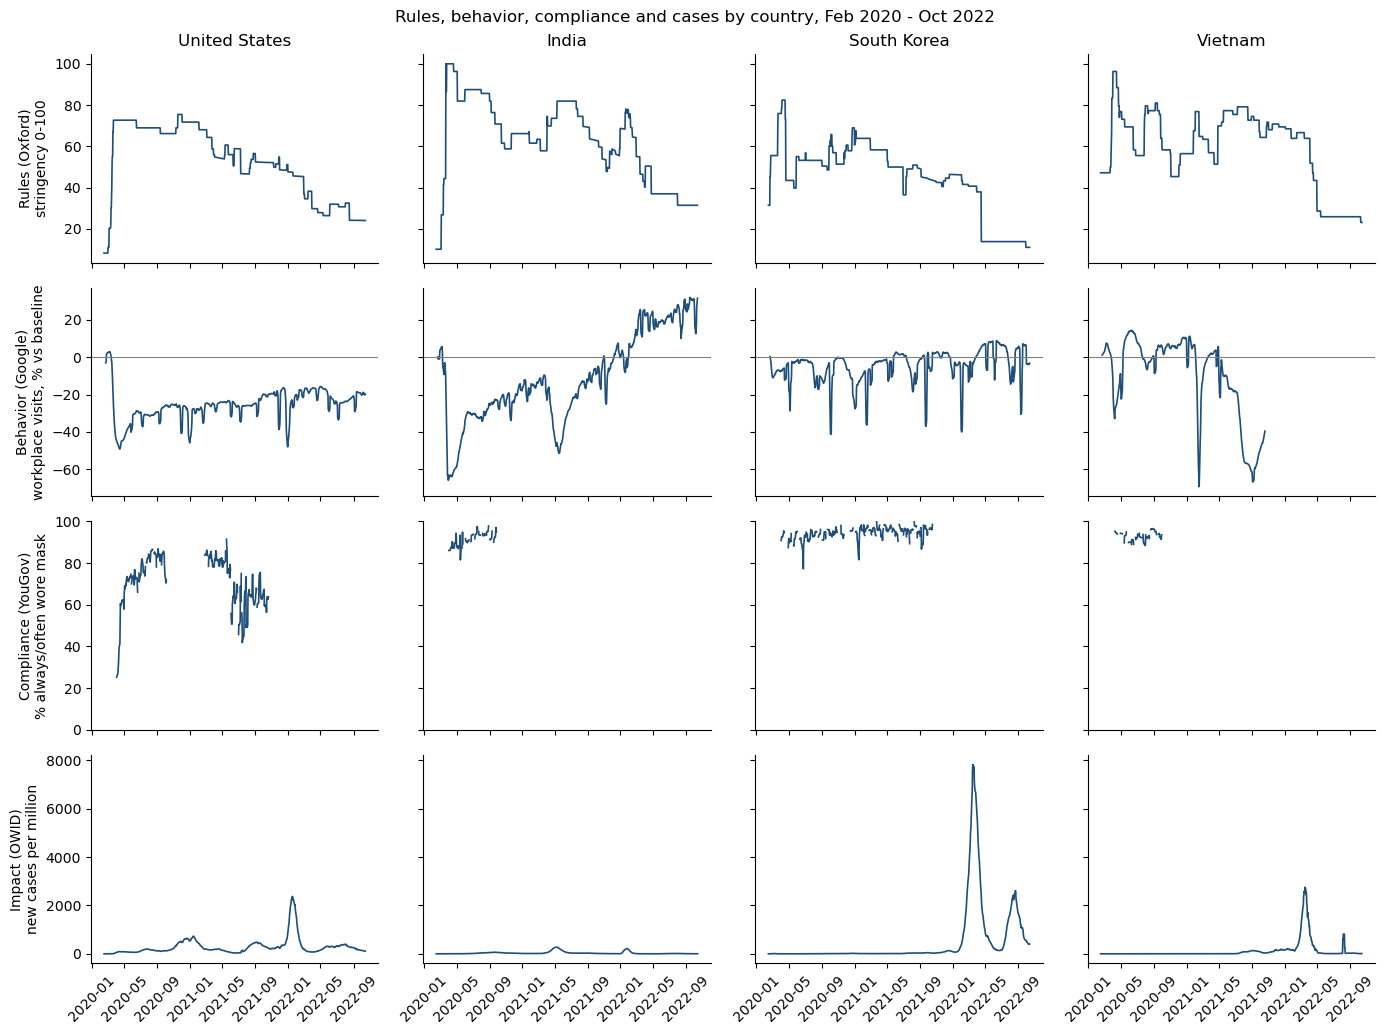

In [80]:
import matplotlib.pyplot as plt

# Google drops every weekend, so smooth it with a 7-day average (like OWID's cases)
daily['workplaces_7d'] = (daily.groupby('country')['workplaces']
                          .transform(lambda s: s.rolling(7).mean()))

# YouGov: 7-day average weighted by responses per day, so tiny-sample days don't spike
daily['_mask_x_n'] = daily['wore_mask_outside'] * daily['survey_n']
daily['_n_mask'] = daily['survey_n'].where(daily['wore_mask_outside'].notna())
roll = daily.groupby('country')[['_mask_x_n', '_n_mask']].transform(lambda s: s.rolling(7, min_periods=1).sum())
daily['mask_7d'] = (roll['_mask_x_n'] / roll['_n_mask']).where(roll['_n_mask'] >= 50) * 100
daily = daily.drop(columns=['_mask_x_n', '_n_mask'])

rows = [('stringency_index', 'Rules (Oxford)\nstringency 0-100'),
        ('workplaces_7d', 'Behavior (Google)\nworkplace visits, % vs baseline'),
        ('mask_7d', 'Compliance (YouGov)\n% always/often wore mask'),
        ('new_cases_smoothed_per_million', 'Impact (OWID)\nnew cases per million')]
countries = ['United States', 'India', 'South Korea', 'Vietnam']

fig, axes = plt.subplots(len(rows), 4, figsize=(14, 10.5), sharex=True, sharey='row')
for r, (column, label) in enumerate(rows):
    for c, country in enumerate(countries):
        ax = axes[r, c]
        one = daily[daily.country == country]
        ax.plot(one['date'], one[column], color='#1f4e79', linewidth=1.2)
        if column == 'workplaces_7d':
            ax.axhline(0, color='gray', linewidth=0.8)   # 0 = normal (pre-COVID)
        if column == 'mask_7d':
            ax.set_ylim(0, 100)
        if r == 0: ax.set_title(country)
        if c == 0: ax.set_ylabel(label)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(axis='x', labelrotation=45)
fig.suptitle('Rules, behavior, compliance and cases by country, Feb 2020 - Oct 2022')
fig.tight_layout()
plt.show()

### When to use `dropna` on `daily`

`daily` is clean and ready, since most of data blank isn't wrong or missing it just never get recorded. **Never overwrite it.** Make a copy for each chart.

Before each chart, ask: **"Are all the countries and columns using the same days?"**
- **Yes:** nothing to do.
- **No:** cut to the same days.

| Situation | What to do | Example |
|---|---|---|
| Line chart | Nothing. Blanks show as a gap | `daily.plot(...)` |
| Comparing **countries** on a column with blanks (e.g. `workplaces`) | Same **date window** for all 4 countries | `same_window = daily[daily.date <= '2021-10-19']` |
| Comparing **two columns** (scatter, correlation) | `dropna` on **those columns only** | `vax_vs_cases = daily.dropna(subset=['people_vaccinated_per_hundred', 'new_cases_smoothed_per_million'])` |

**Why:** `.mean()` skips blanks. So without a shared window, Vietnam's average `workplaces` would cover only Feb 2020 – Oct 2021, while the others cover up to Oct 2022. That's not a fair comparison.

**Don't:**
- `daily = daily.dropna(...)`: overwrites `daily`
- `daily.dropna()`: no day is complete in every column, so you'd lose rows you need

In [88]:
# Adding country colors for all charts
country_colors = {"India": "#E69F00", "South Korea": "#0072B2",
                  "United States": "#009E73", "Vietnam": "#CC79A7"}  # colorblind-friendly palette
country_order = list(country_colors)

STORY :

* Start with case counts, how were each country affected by covid cases?
NEED - using smoothed or normalized data
* Then the stringency story: how did governments react?
Alex has this visual
* How long were each of the countries experiencing different types of stringency measures? 
Alex has this visual
* How did people respond to the stringency
Brisa to create 1 or 2 add mask wearing/self-reports gatherings/behavior
Duy add 1-2 mobility data
Alex’s people staying home during lock downs (Alex – explore Korea compliance data from YouGov to back up or throw out the mobility data)
* How did vaccination rates help loosen stringency?
Rashmi has this visual 
* Stringency has lessened, but did deaths also decrease?
Rashmi has this visual 


Plot 1 - Cases

Plot 2

Plot 3

Plot 4

Plot 5

Plot 6

Plot 7

Plot 8

Plot 9

Plot 10